Tugas Preprocessing Data Saham
______________________________
Nama : Joseph Seri Aprillio De Ornay
NIM  : 225314118
_______________________________
Tahapan tugas :
1. Menggunakan library yfinance untuk mengambil data keuangan dari yahoo finance.
2. Memasukan Kode perusahaan yang dituju.
3. Mengambil data historis selama periode waktu tertentu.
4. Melakukan preprocessing data.
5. Melakukan Plot data untuk prediksi EMA dan tren pada waktu tertentu. 

Memasukan library yang dibutuhkan untuk mengambil data keuangan dari yahoo finance, memproses data dalam bentuk data frame, melakukan kalkulasi data, dan membuat plot untuk visualisasi hasil.

In [2]:
import yfinance as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Menentukan perusahaan yang akan dikenai proses persiapan data, forecasting, dan visualisasi. Pada tugas ini, saya menggunakan dataset Saham dari PT.Bank Central Asia dengan kode BBCA.JK. 

In [3]:
saham = tf.Ticker('BBCA.JK')
fullinfo = saham.get_info()
print(fullinfo['longName'])

PT Bank Central Asia Tbk


Mengambil periode 5 tahun kebelakang sebagai data yang akan diproses, mengubah menjadi format data frame, dan menampilkan 5 baris awal dari data frame.

In [4]:
historis_data = saham.history(period='5y')
df_historis_data = pd.DataFrame(historis_data)
df_historis_data.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Date,,,,,,,
2020-03-24 00:00:00+07:00,3871.917429,4346.118552,3871.917429,3915.422119,253971000,0.0,0.0
2020-03-26 00:00:00+07:00,4045.936557,4694.156500,4045.936557,4594.095703,331633000,0.0,0.0
2020-03-27 00:00:00+07:00,4663.702253,5129.202385,4659.351784,4794.216309,269683000,0.0,0.0
2020-03-30 00:00:00+07:00,4768.114120,4833.371156,4485.333629,4781.165527,159964500,0.0,0.0
2020-03-31 00:00:00+07:00,4924.730225,4968.234909,4772.463831,4807.267578,182638500,0.0,0.0


Melihat kolom, jumlah nilai non-null, dan tipe data pada data frame

In [5]:
df_historis_data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1208 entries, 2020-03-24 00:00:00+07:00 to 2025-03-24 00:00:00+07:00
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Open          1208 non-null   float64
 1   High          1208 non-null   float64
 2   Low           1208 non-null   float64
 3   Close         1208 non-null   float64
 4   Volume        1208 non-null   int64  
 5   Dividends     1208 non-null   float64
 6   Stock Splits  1208 non-null   float64
dtypes: float64(6), int64(1)
memory usage: 75.5 KB


Memasukan data date (tanggal) pada dataframe final.

In [6]:
df_final=df_historis_data.reset_index()
df_final.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2020-03-24 00:00:00+07:00,3871.917429,4346.118552,3871.917429,3915.422119,253971000,0.0,0.0
1,2020-03-26 00:00:00+07:00,4045.936557,4694.156500,4045.936557,4594.095703,331633000,0.0,0.0
2,2020-03-27 00:00:00+07:00,4663.702253,5129.202385,4659.351784,4794.216309,269683000,0.0,0.0
3,2020-03-30 00:00:00+07:00,4768.114120,4833.371156,4485.333629,4781.165527,159964500,0.0,0.0
4,2020-03-31 00:00:00+07:00,4924.730225,4968.234909,4772.463831,4807.267578,182638500,0.0,0.0


Melakukan pengecekan informasi data frame final yang didapati bahwa tidak terdapat nilai null pada data sehingga tidak perlu diberlakukan drop nilai null. 

In [7]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1208 entries, 0 to 1207
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype                       
---  ------        --------------  -----                       
 0   Date          1208 non-null   datetime64[ns, Asia/Jakarta]
 1   Open          1208 non-null   float64                     
 2   High          1208 non-null   float64                     
 3   Low           1208 non-null   float64                     
 4   Close         1208 non-null   float64                     
 5   Volume        1208 non-null   int64                       
 6   Dividends     1208 non-null   float64                     
 7   Stock Splits  1208 non-null   float64                     
dtypes: datetime64[ns, Asia/Jakarta](1), float64(6), int64(1)
memory usage: 75.6 KB


Terlihat dari 1208 data saham BCA bahwa semuanya bukan merupakan nilai duplikat.  

In [8]:
print((~df_final.duplicated(keep=False)).sum())  

1208


Menggunakan forecasting data saham BCA menggunakan EMA (Exponential Moving Average) dengan span 9, 12, dan 30. Kemudian menampilkan hasil dalam bentul visualisasi plot. 


Close price adalah harga terakhir dalam suatu transaksi pada hari yang dituju. Sehingga ketika dibuat dalam bentuk grafik dapat memberikan gambaran singkat mengenai nilai perusahaan, tren yang telah, dan sedang berjalan. Karena hal itu dapat dijadikan sebagai kajian untuk membeli atau menjual. Melihat dari hasil para grafik EMA 9 memotong EMA 30 selama beberapa kali pada periode waktu yang berbeda. Hal ini menjadi petunjuk akan keadaan pasar saat itu yang terjadi prediksi kemungkinan besar orang telah menjual atau membeli saham. Kecenderungan dari prediksi EMA yakni apabila terjadi prediksi penurunan yang cukup dalam pada market. Maka, EMA akan memprediksikan untuk menjual, sedangkan jika ada kemungkinan terjadi kenaikan maka EMA akan memprediksi untuk membeli. 

C:\Users\rio\AppData\Local\Temp\ipykernel_3828\4046464444.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_periode[f'EMA_{span}'] = data_periode['Low'].ewm(span=span, adjust=False).mean()
C:\Users\rio\AppData\Local\Temp\ipykernel_3828\4046464444.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_periode[f'EMA_{span}'] = data_periode['Low'].ewm(span=span, adjust=False).mean()
C:\Users\rio\AppData\Local\Temp\ipykernel_3828\4046464444.py:13: SettingWithCopyWarning: 
A value is trying to be set 

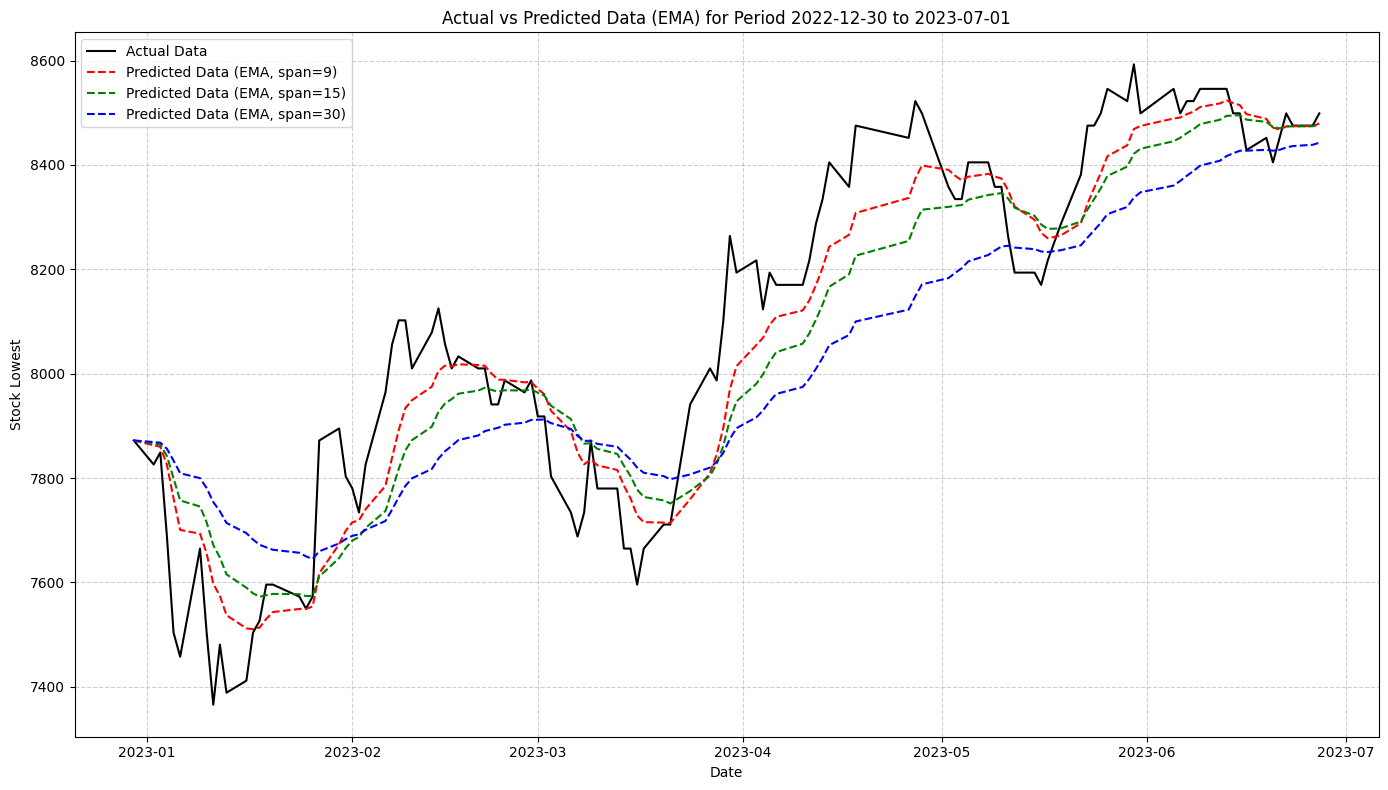

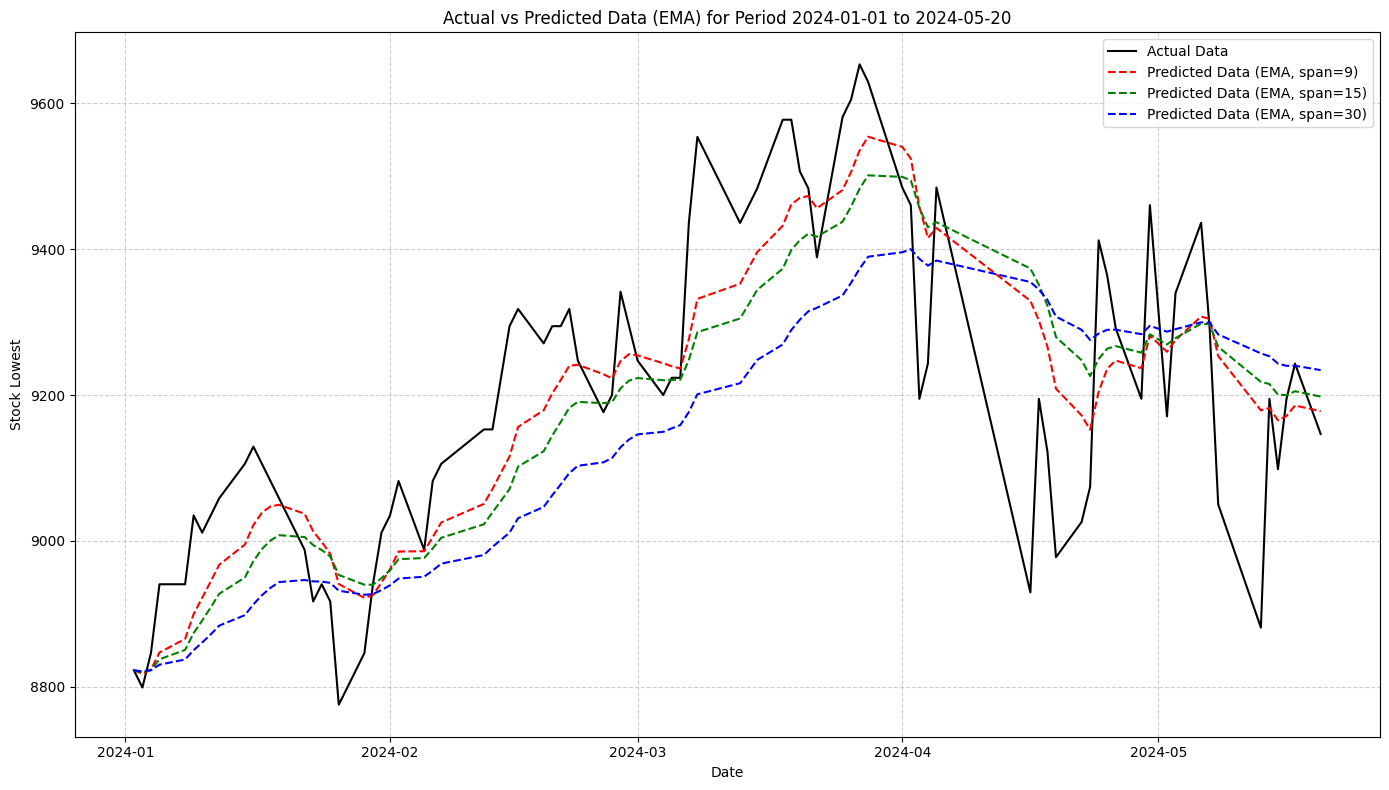

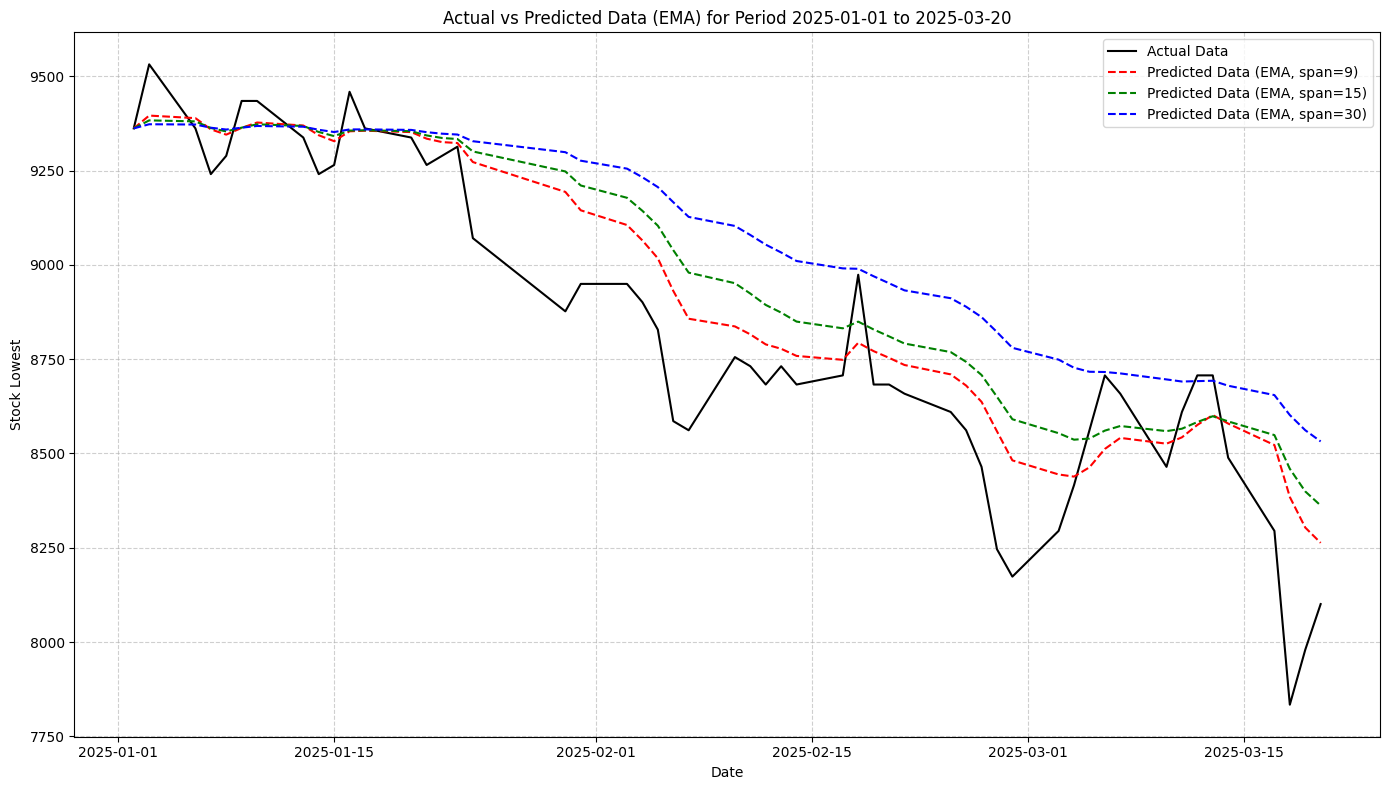

In [91]:
periode_list = [
    ('2022-12-30', '2023-07-01'),
    ('2024-01-01', '2024-05-20'),
    ('2025-01-01', '2025-03-20')
]

span_values = [9, 15, 30]

for i, (start_date, end_date) in enumerate(periode_list, 1):
    data_periode = df_final[(df_final['Date'] >= start_date) & (df_final['Date'] <= end_date)]
    
    for span in span_values:
        data_periode[f'EMA_{span}'] = data_periode['Low'].ewm(span=span, adjust=False).mean()

    plt.figure(figsize=(14, 8))
    plt.plot(data_periode['Date'], data_periode['Low'], label='Actual Data', color='black')
    
    colors = ['red', 'green', 'blue']
    for j, span in enumerate(span_values):
        plt.plot(data_periode['Date'], data_periode[f'EMA_{span}'], label=f'Predicted Data (EMA, span={span})', color=colors[j], linestyle='--')

    plt.title(f'Actual vs Predicted Data (EMA) for Period {start_date} to {end_date}')
    plt.xlabel('Date')
    plt.ylabel('Stock Lowest')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()

plt.show()

In [84]:
df_final["ema_9"] = df_final["Close"].ewm(span=9, adjust=False).mean()
df_final["ema_12"] = df_final["Close"].ewm(span=12, adjust=False).mean()
df_final["ema_30"] = df_final["Close"].ewm(span=30, adjust=False).mean()

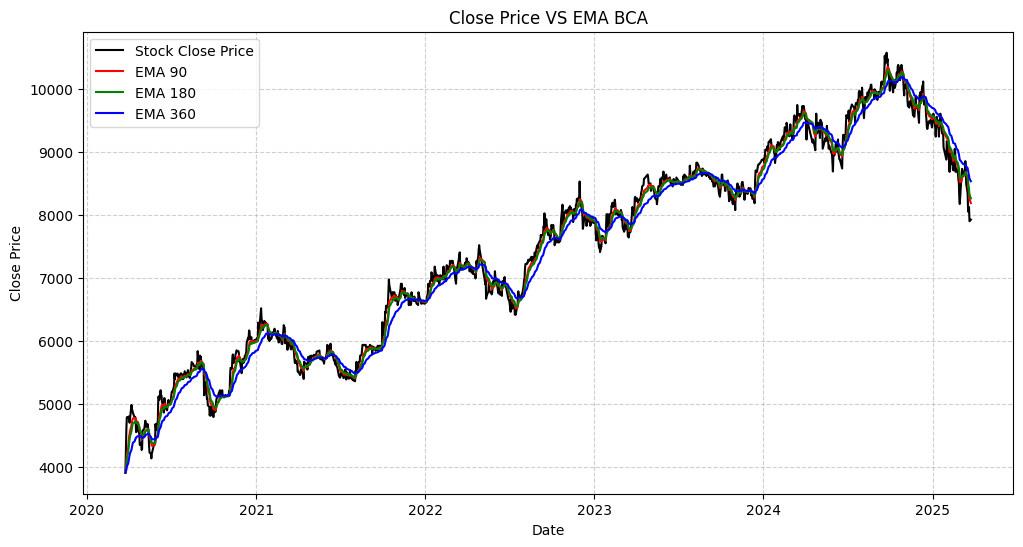

In [85]:
#Actual Data VS Predictied Data
plt.figure(figsize=(12, 6))
plt.plot(df_final["Date"], df_final["Close"], color="black", label="Stock Close Price")
plt.plot(df_final["Date"], df_final["ema_9"], color="red", label="EMA 90")
plt.plot(df_final["Date"], df_final["ema_12"], color="green", label="EMA 180")
plt.plot(df_final["Date"], df_final["ema_30"], color="blue", label="EMA 360")
plt.title("Close Price VS EMA BCA")
plt.xlabel("Date")
plt.ylabel("Close Price")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

Melihat harga tertinggi dan terendah berguna bagi investor untuk melakukan analisis teknikal untuk melihat sinyal bullish atau bearish, menilai votalitas saham, mengindikasikan pola harga, hingga membantu menentukan entry dan exit point. 

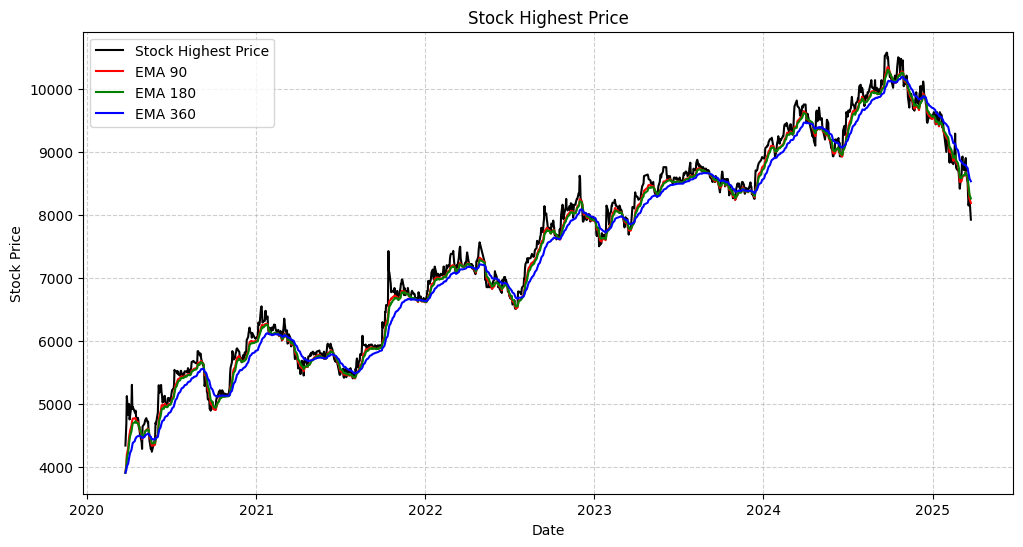

In [86]:
plt.figure(figsize=(12, 6))
plt.plot(df_final["Date"], df_final["High"], color="black", label="Stock Highest Price")
plt.plot(df_final["Date"], df_final["ema_9"], color="red", label="EMA 90")
plt.plot(df_final["Date"], df_final["ema_12"], color="green", label="EMA 180")
plt.plot(df_final["Date"], df_final["ema_30"], color="blue", label="EMA 360")
plt.title("Stock Highest Price")
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

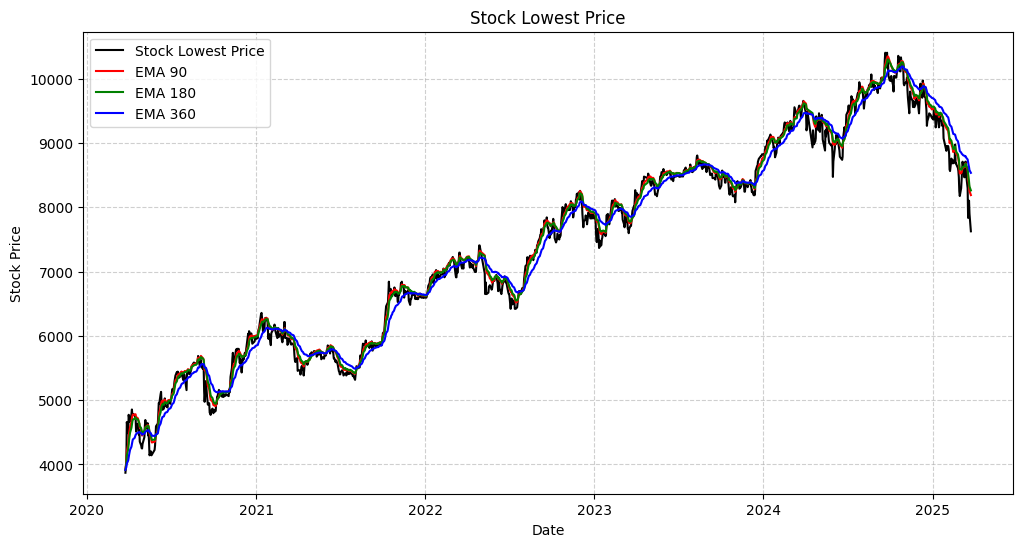

In [87]:
plt.figure(figsize=(12, 6))
plt.plot(df_final["Date"], df_final["Low"], color="black", label="Stock Lowest Price")
plt.plot(df_final["Date"], df_final["ema_9"], color="red", label="EMA 90")
plt.plot(df_final["Date"], df_final["ema_12"], color="green", label="EMA 180")
plt.plot(df_final["Date"], df_final["ema_30"], color="blue", label="EMA 360")
plt.title("Stock Lowest Price")
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

Membuat trendline dari grafik dengan beberapa rentang waktu yang berbeda. Terdapat 3 periode waktu yang ditampilkan, namun menghasilkan trendline yang berbeda terkhususnya pada awal tahun 2025. Tren pada awal tahun 2025 cenderung menurun yang memiliki kaitan erat dengan isu perusahaan dan negara, penurunan laba, peningkatan hutang, hingga kepercayaan investor. Namun, jika berkaca dari keadaan saat ini dan dikaitkan dengan Outlook perbankan 2025 BCA :Tahun Penuh Tantangan. Sekiranya dapat menjelaskan mengapa penurunan dapat terjadi yang dikuatkan dengan kutipan "Tahun 2025 dimulai dengan prospek global yang menantang, ditandai dengan dolar AS yang kuat, ketidakpastian politik dan melemahnya harga komoditas".

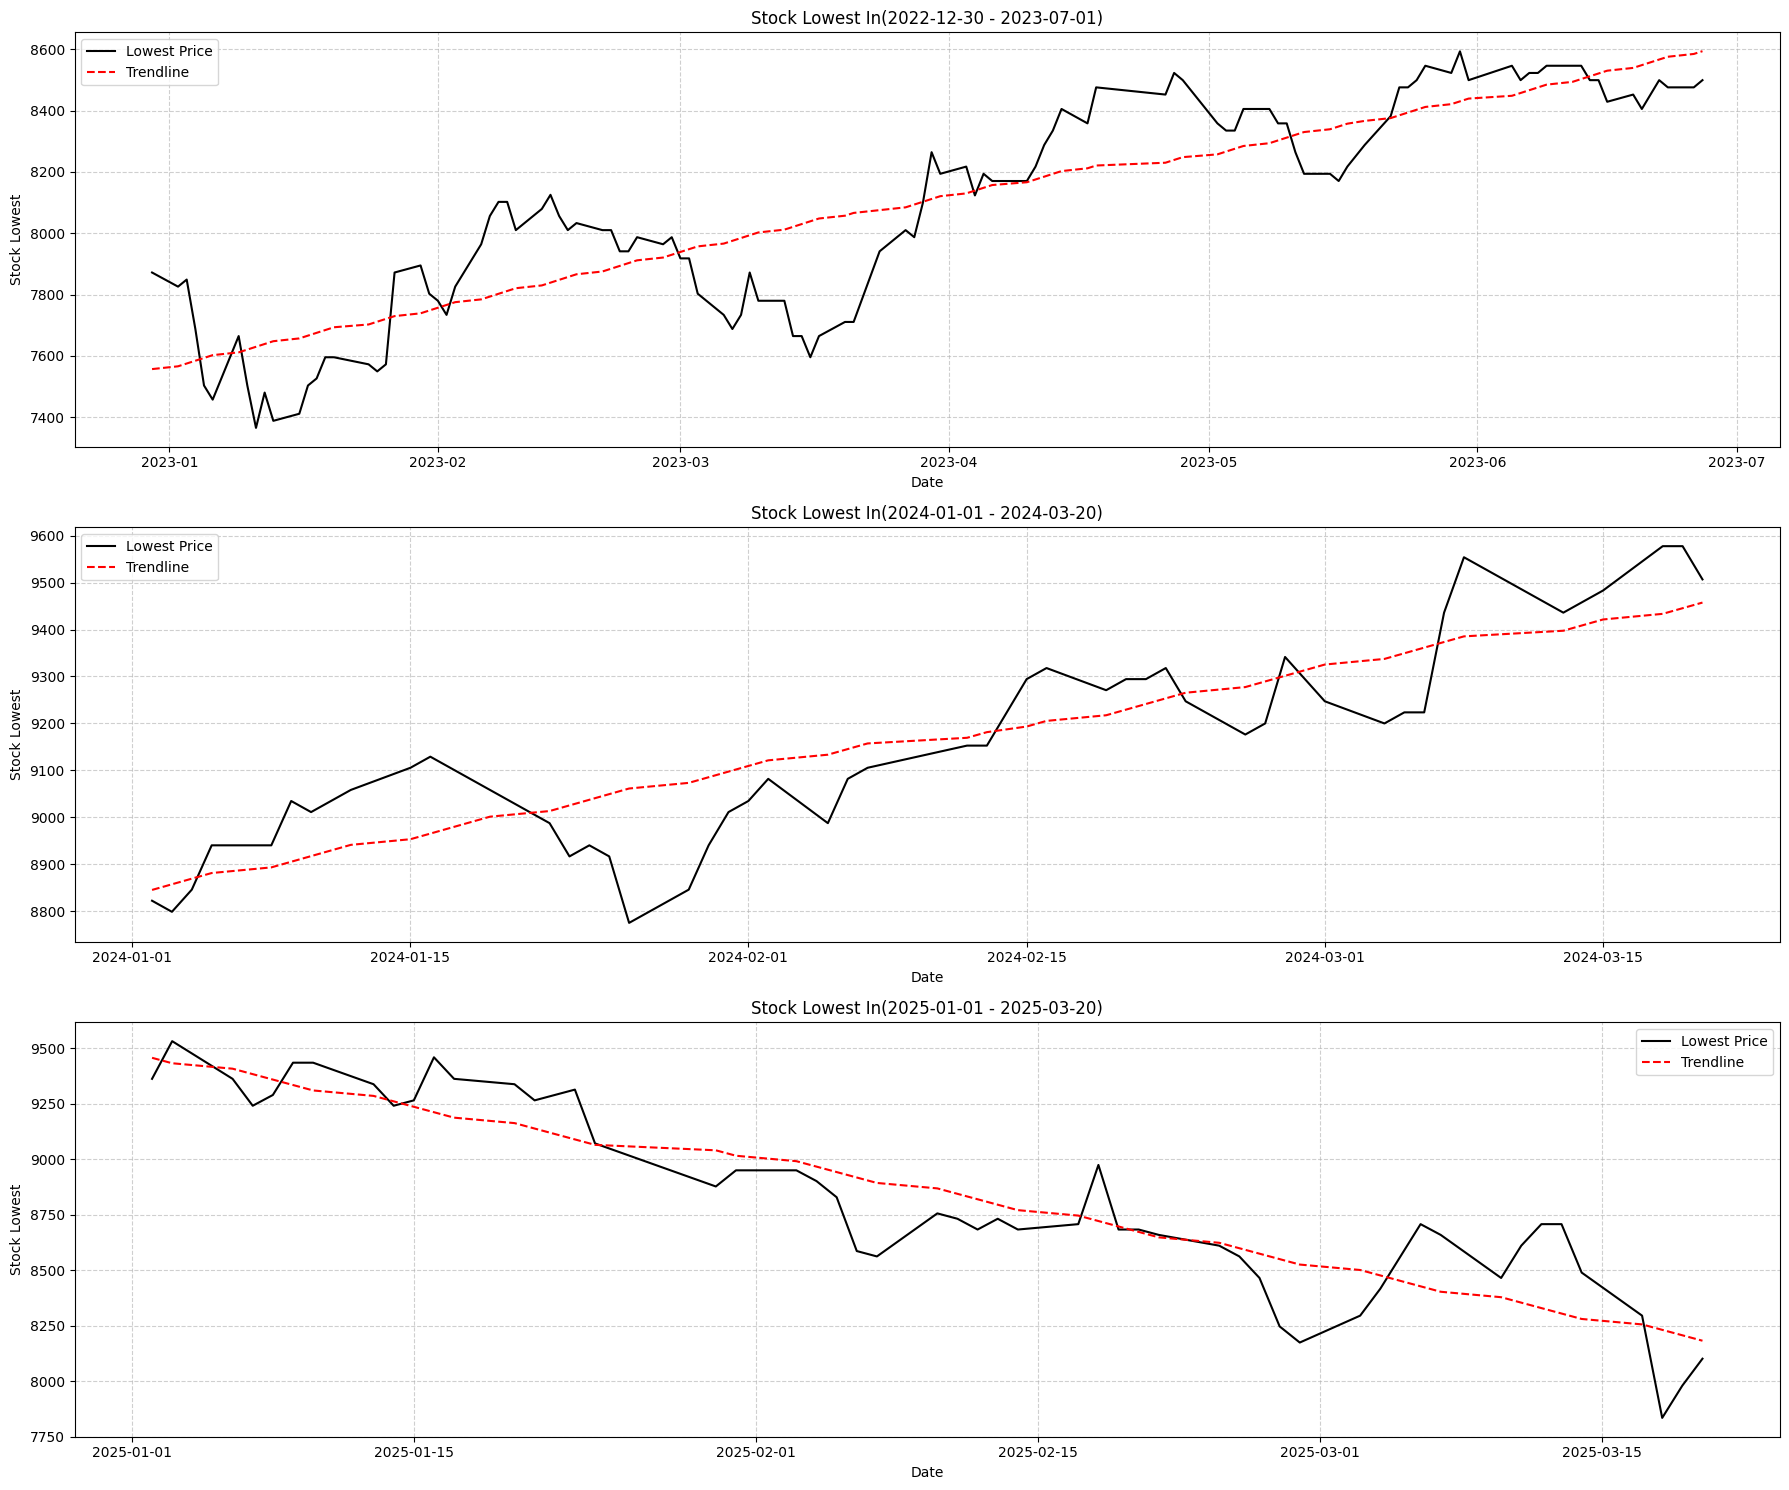

In [88]:
periode_list = [
    ('2022-12-30', '2023-07-01'),
    ('2024-01-01', '2024-03-20'),
    ('2025-01-01', '2025-03-20')
]

plt.figure(figsize=(18, 15))

for i, (start_date, end_date) in enumerate(periode_list, 1):
    data_periode = df_final[(df_final['Date'] >= start_date) & (df_final['Date'] <= end_date)]
    x = np.arange(len(data_periode))
    
    plt.subplot(3, 1, i)
    plt.plot(data_periode['Date'], data_periode['Low'], color='black', label='Lowest Price')
    plt.title(f"Stock Lowest In({start_date} - {end_date})")
    plt.xlabel("Date")
    plt.ylabel("Stock Lowest")
    plt.grid(True, linestyle="--", alpha=0.6)

    z = np.polyfit(x, data_periode['Low'], 1)
    p = np.poly1d(z)
    plt.plot(data_periode['Date'], p(x), "r--", label="Trendline")
    plt.legend()

plt.tight_layout()
plt.show()